# 04 Logistic regression on the G0–G3 feature sets

This notebook tunes and validates logistic regression on the four cumulative feature sets built in
`02_feature_engineering.ipynb`: G0 raw columns (197) → G1 + row-level features (224) → G2 + card and device
history (234) → G3 + customer history (252). All six model notebooks (04 to 09) follow the same steps and call the
same code in `src/`, so their results can be compared directly in `10_model_comparison.ipynb`.

- **Data:** `data/processed/features_v2.parquet` (build it with `02_feature_engineering.ipynb`). `src.feature_sets`
  drops the test block before anything else sees it, so this notebook never touches it.
- **Splits:** `src/split.py`. Training block = the first 472,432 rows by time; validation = the next 59,054.
- **Every fit** appends one row to `results/log.csv`. Rerunning the notebook skips anything already logged, so it
  can be stopped and restarted. Validation scores are saved to `results/preds/` (not in git) for the comparison
  notebook and a possible ensemble.

In [4]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Import the model library before anything else: on macOS some model libraries clash with PyTorch's
# threading library if PyTorch is loaded first (see tests/conftest.py).
from src.models import logreg as model

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sklearn.metrics import precision_recall_curve

from src import data, experiment, feature_sets as fs, importance, segments
from src.metrics import top_rows

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

## 1. Settings

- `FEATURE_SETS`: the sets to validate on.
- `TUNE_ON`: `"G3"` tunes once, on the full set, and validates those settings on every set, so the sets are
  compared with the model held fixed. `None` tunes every set separately (four times the tuning cost).
- `GRID`: the settings tried during tuning, defined in the model's file in `src/models/` (logistic regression 11,
  random forest 12, MLP 16, LightGBM, XGBoost and CatBoost 20 each, so every model gets a comparable search). For a quick trial, use e.g. `model.GRID[:2]`, but log such a trial to a
  separate file (`LOG_PATH`) so it doesn't mix with the real runs.
- `SEEDS`: the validation seeds (0, 1, 2 for the group's results).
- `SAVE_OOF`: also save the time-CV fold scores of the chosen settings (4 extra fits per set), needed to train a
  stacking model later.
- `IMPORTANCE_SET`, `IMPORTANCE_ROWS`: the feature set and the number of validation rows used for feature importance
  (section 6). More rows give steadier numbers but take longer.

In [5]:
FEATURE_SETS = ["G0", "G1", "G2", "G3"]
TUNE_ON = "G3"
GRID = model.GRID
SEEDS = [0, 1, 2]
SAVE_OOF = True
LOG_PATH = experiment.LOG_PATH          # results/log.csv
PREDS_DIR = experiment.PREDS_DIR        # results/preds/
MODELS_DIR = experiment.MODELS_DIR      # results/models/ (fitted models, reused by section 6)
IMPORTANCE_SET = FEATURE_SETS[-1]       # G3 by default: all features
IMPORTANCE_ROWS = 20_000
IMPORTANCE_DIR = ROOT / "results" / "importance"

print(f"{model.NAME}: {len(GRID)} settings to tune on {TUNE_ON or 'every set'}, seeds {SEEDS}")
print("defaults:", model.DEFAULTS)
pd.DataFrame(GRID)

logreg: 11 settings to tune on G3, seeds [0, 1, 2]
defaults: {'C': 1.0, 'max_iter': 1000}


,C
0,0.001
1,0.003
2,0.010
3,0.030
4,0.100
5,0.300
6,1.000
7,3.000
8,10.000
9,30.000


## 2. Data

In [6]:
df, train_idx, val_idx = fs.load_features()
spec = fs.load_spec()
sets = {name: fs.feature_list(name, spec) for name in FEATURE_SETS}
print(f"rows loaded: {len(df):,} (train {len(train_idx):,}, validation {len(val_idx):,}; test block not loaded)")
print({name: len(cols) for name, cols in sets.items()})

rows loaded: 531,486 (train 472,432, validation 59,054; test block not loaded)
{'G0': 197, 'G1': 224, 'G2': 234, 'G3': 252}


## 3. Model input

**Input:** `LinearPipeline` (`src/data.py`), fitted on each training part only. Numeric columns get median
imputation, a missing-value indicator (for columns with any missing training value) and standard scaling.
Categories with up to 20 training levels are one-hot encoded with a missing column; larger ones (for example
`DeviceInfo`, `fe_v_missing_pattern`) get their training frequency.

**Model:** `src/models/logreg.py`. L2-regularised logistic regression with balanced class weights (lbfgs, up to
1,000 iterations). Grid search over the regularisation strength: 11 values of C from 0.001 to 100.

In [7]:
def make_pipeline(columns):
    return data.LinearPipeline(columns=columns)

## 4. Tune and validate

1. **Tune** with time CV inside the training block (seed 0): the block is cut into 30-day bins, and fold k trains on
   bins 0 to k−1 and scores bin k, so every fold scores months the model hasn't seen (4 folds). The settings with
   the highest mean average precision (PR-AUC) are chosen.
2. **Validate:** refit the chosen settings on the whole training block with each seed and score the validation
   block. The decision threshold (best F1) is picked on the validation block and stored in the log for the final
   test scoring.

Logistic regression has no early stopping, so it trains on the whole training part of every fit.

In [8]:
chosen = experiment.tune_and_validate(model, make_pipeline, df, train_idx, val_idx, sets, GRID,
                                      tune_on=TUNE_ON, seeds=SEEDS, log_path=LOG_PATH,
                                      preds_dir=PREDS_DIR, save_oof=SAVE_OOF)
chosen


logreg/G3: tuning 11 settings with time CV (seed 0)
fold 1 {'C': 0.001} pr_auc=0.3923 (4s)
fold 1 {'C': 0.003} pr_auc=0.3914 (6s)
fold 1 {'C': 0.01} pr_auc=0.3919 (5s)
fold 1 {'C': 0.03} pr_auc=0.3928 (7s)
fold 1 {'C': 0.1} pr_auc=0.3934 (12s)
fold 1 {'C': 0.3} pr_auc=0.3937 (15s)
fold 1 {'C': 1} pr_auc=0.3932 (27s)
fold 1 {'C': 3} pr_auc=0.3923 (23s)
fold 1 {'C': 10} pr_auc=0.3916 (22s)
fold 1 {'C': 30} pr_auc=0.3925 (26s)
fold 1 {'C': 100} pr_auc=0.3918 (26s)
fold 2 {'C': 0.001} pr_auc=0.4021 (7s)
fold 2 {'C': 0.003} pr_auc=0.4061 (5s)
fold 2 {'C': 0.01} pr_auc=0.4132 (9s)
fold 2 {'C': 0.03} pr_auc=0.4200 (15s)
fold 2 {'C': 0.1} pr_auc=0.4193 (27s)
fold 2 {'C': 0.3} pr_auc=0.4117 (25s)
fold 2 {'C': 1} pr_auc=0.4053 (32s)
fold 2 {'C': 3} pr_auc=0.4008 (43s)
fold 2 {'C': 10} pr_auc=0.3987 (41s)
fold 2 {'C': 30} pr_auc=0.3970 (41s)
fold 2 {'C': 100} pr_auc=0.3978 (40s)
fold 3 {'C': 0.001} pr_auc=0.3928 (6s)
fold 3 {'C': 0.003} pr_auc=0.3988 (7s)
fold 3 {'C': 0.01} pr_auc=0.4045 (13s)
f

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


fold 4 {'C': 0.001} pr_auc=0.4287 (9s)
fold 4 {'C': 0.003} pr_auc=0.4310 (13s)
fold 4 {'C': 0.01} pr_auc=0.4290 (19s)
fold 4 {'C': 0.03} pr_auc=0.4249 (25s)
fold 4 {'C': 0.1} pr_auc=0.4229 (37s)
fold 4 {'C': 0.3} pr_auc=0.4208 (49s)
fold 4 {'C': 1} pr_auc=0.4184 (46s)
fold 4 {'C': 3} pr_auc=0.4210 (54s)
fold 4 {'C': 10} pr_auc=0.4169 (66s)
fold 4 {'C': 30} pr_auc=0.4202 (61s)
fold 4 {'C': 100} pr_auc=0.4180 (68s)
logreg/G3: best {'C': 0.03}
logreg/G0 seed 0: val pr_auc=0.3395 auroc=0.8326 (23s)
logreg/G0 seed 1: val pr_auc=0.3395 auroc=0.8326 (22s)
logreg/G0 seed 2: val pr_auc=0.3395 auroc=0.8326 (22s)
logreg/G1 seed 0: val pr_auc=0.3521 auroc=0.8399 (32s)
logreg/G1 seed 1: val pr_auc=0.3521 auroc=0.8399 (33s)
logreg/G1 seed 2: val pr_auc=0.3521 auroc=0.8399 (32s)
logreg/G2 seed 0: val pr_auc=0.3506 auroc=0.8386 (30s)
logreg/G2 seed 1: val pr_auc=0.3506 auroc=0.8386 (29s)
logreg/G2 seed 2: val pr_auc=0.3506 auroc=0.8386 (29s)
logreg/G3 seed 0: val pr_auc=0.3525 auroc=0.8401 (31s)
logre

{'G0': {'C': 0.03}, 'G1': {'C': 0.03}, 'G2': {'C': 0.03}, 'G3': {'C': 0.03}}

## 5. Results

All numbers below are read back from `results/log.csv` (and, for 5.4, the saved validation scores). Precision in
the top 1% is derived from the logged recall in the top 1% (precision = recall × fraud rows ÷ rows flagged), so it
ranks models exactly as recall does but reads more easily: recall in the top 1% is capped well below 1, because the
top 1% of rows holds fewer rows than there are fraud cases.

### 5.1 Tuning
Means over the 4 time-CV folds for the 5 best settings on each tuned set; `chosen` marks the settings validated below.

In [9]:
sizes = experiment.block_sizes(df, train_idx, val_idx)
cv, val = experiment.run_summary(model.NAME, FEATURE_SETS, LOG_PATH, sizes=sizes)
chosen_key = {name: json.dumps(p, sort_keys=True) for name, p in chosen.items()}
cv["chosen"] = [chosen_key.get(r.feature_set) == r.settings for r in cv.itertuples()]
display(cv.groupby("feature_set").head(5).round(4))

,feature_set,settings,cv_pr_auc,cv_std,cv_auroc,cv_recall_top1pct,cv_precision_top1pct,folds,chosen
0,G3,"{""C"": 0.03}",0.4110,0.0145,0.8563,0.2071,0.7958,4,True
1,G3,"{""C"": 0.1}",0.4105,0.0134,0.8557,0.2073,0.7970,4,False
2,G3,"{""C"": 0.01}",0.4097,0.0156,0.8562,0.2058,0.7908,4,False
3,G3,"{""C"": 0.3}",0.4078,0.0114,0.8545,0.2064,0.7936,4,False
4,G3,"{""C"": 0.003}",0.4068,0.0172,0.8555,0.2036,0.7820,4,False


### 5.2 Validation block, chosen settings
Mean ± sample sd over the seeds. Precision and recall "at threshold" use the F1-best threshold picked on the validation
block itself, so they are slightly optimistic; the test block is scored once with the stored threshold after the freeze.

In [10]:
val = val[[chosen_key.get(r.feature_set) == r.settings for r in val.itertuples()]]
val = val.set_index("feature_set").reindex(FEATURE_SETS)
labels = {"pr_auc": "PR-AUC", "auroc": "AUROC", "recall_top1pct": "recall top 1%",
          "precision_top1pct": "precision top 1%", "precision": "precision at threshold",
          "recall": "recall at threshold"}
table = pd.DataFrame({label: val[f"{m}_mean"].map("{:.4f}".format) + " ± " + val[f"{m}_std"].map("{:.4f}".format)
                      for m, label in labels.items()})
table["threshold"] = val["threshold_mean"].round(4)
table["seeds"] = val["seeds"]
n_val, fraud_val = sizes["val"]
print(f"Validation block: {fraud_val:,} fraud in {n_val:,} rows. The top 1% is {top_rows(n_val):,} rows, "
      f"so recall in the top 1% is at most {top_rows(n_val) / fraud_val:.3f}.")
display(table)

Validation block: 1,851 fraud in 59,054 rows. The top 1% is 591 rows, so recall in the top 1% is at most 0.319.


,PR-AUC,AUROC,recall top 1%,precision top 1%,precision at threshold,recall at threshold,threshold,seeds
feature_set,,,,,,,,
G0,0.3395 ± 0.0000,0.8326 ± 0.0000,0.2075 ± 0.0000,0.6497 ± 0.0000,0.4131 ± 0.0000,0.3160 ± 0.0000,0.8803,3
G1,0.3521 ± 0.0000,0.8399 ± 0.0000,0.2102 ± 0.0000,0.6582 ± 0.0000,0.4168 ± 0.0000,0.3355 ± 0.0000,0.9097,3
G2,0.3506 ± 0.0000,0.8386 ± 0.0000,0.2091 ± 0.0000,0.6548 ± 0.0000,0.4180 ± 0.0000,0.3279 ± 0.0000,0.9142,3
G3,0.3525 ± 0.0000,0.8401 ± 0.0000,0.2112 ± 0.0000,0.6616 ± 0.0000,0.4893 ± 0.0000,0.2966 ± 0.0000,0.9377,3


**Precision–recall curves** on the validation block (seed 0), one per feature set. PR-AUC is the area under each
curve; the dashed line is a model with no skill (precision = fraud rate).

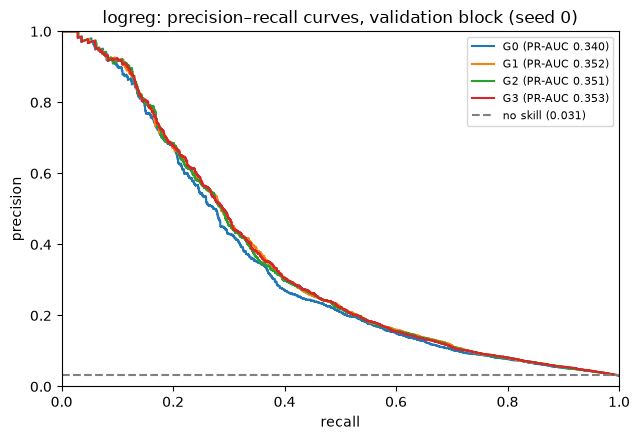

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name in FEATURE_SETS:
    path = PREDS_DIR / f"{model.NAME}_{name}_val_seed0.parquet"
    if path.exists():
        p = pd.read_parquet(path)
        precision, recall, _ = precision_recall_curve(p["isFraud"], p["score"])
        ax.plot(recall, precision, label=f"{name} (PR-AUC {val.loc[name, 'pr_auc_mean']:.3f})", lw=1.5)
ax.axhline(fraud_val / n_val, ls="--", color="grey", label=f"no skill ({fraud_val / n_val:.3f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"{model.NAME}: precision–recall curves, validation block (seed 0)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 5.3 What each feature group adds
Change in mean validation PR-AUC from one set to the next (same settings on every set when `TUNE_ON` is a set name).

,G0 → G1,G1 → G2,G2 → G3,G0 → G3
change in PR-AUC,0.0126,-0.0016,0.002,0.013


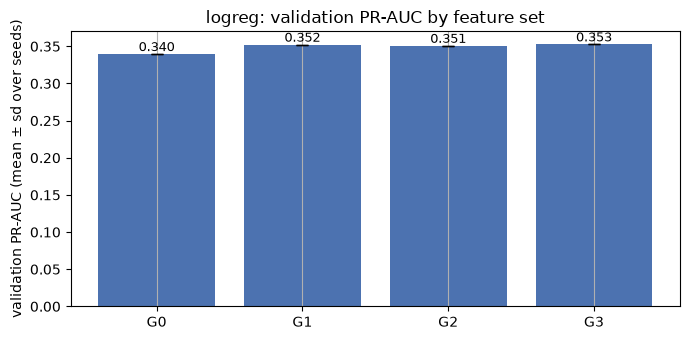

In [12]:
pr = val["pr_auc_mean"]
gains = {f"{a} → {b}": pr[b] - pr[a] for a, b in zip(FEATURE_SETS[:-1], FEATURE_SETS[1:])}
if len(FEATURE_SETS) > 2:
    gains[f"{FEATURE_SETS[0]} → {FEATURE_SETS[-1]}"] = pr[FEATURE_SETS[-1]] - pr[FEATURE_SETS[0]]
display(pd.DataFrame([gains], index=["change in PR-AUC"]).round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(val.index, val["pr_auc_mean"], yerr=val["pr_auc_std"].fillna(0), color="#4C72B0", capsize=4)
for x, y in zip(val.index, val["pr_auc_mean"]):
    ax.text(x, y, f"{y:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("validation PR-AUC (mean ± sd over seeds)")
ax.set_title(f"{model.NAME}: validation PR-AUC by feature set")
ax.grid(axis="x")
fig.tight_layout()
plt.show()

### 5.4 Known vs unknown customers
A validation row is **known** if its `uid` appears in the training block (`src/segments.py`). PR-AUC is the mean over
the seeds, with a 95% bootstrap interval over rows (`N_BOOT` resamples). `10_model_comparison.ipynb` shows the same
split for all models side by side.

In [13]:
N_BOOT = 200
known = segments.known_uid(df["uid"].iloc[val_idx], set(df["uid"].iloc[train_idx]))
rows = []
for name in FEATURE_SETS:
    paths = [PREDS_DIR / f"{model.NAME}_{name}_val_seed{s}.parquet" for s in SEEDS]
    if not all(p.exists() for p in paths):
        print(f"{name}: validation scores not saved for every seed, skipped")
        continue
    preds = [pd.read_parquet(p) for p in paths]
    if not all((p["TransactionID"].to_numpy() == df["TransactionID"].iloc[val_idx].to_numpy()).all() for p in preds):
        raise ValueError(f"{name}: saved scores don't match the validation rows")
    t = segments.segment_pr_auc(preds[0]["isFraud"].to_numpy(), [p["score"].to_numpy() for p in preds], known,
                                n_boot=N_BOOT)
    rows.append(t.assign(feature_set=name))
if rows:
    seg = pd.concat(rows, ignore_index=True)
    display(seg.groupby("segment")[["rows", "fraud"]].first())
    seg["PR-AUC [95% interval]"] = (seg["pr_auc"].map("{:.4f}".format) + " [" + seg["low"].map("{:.3f}".format)
                                    + ", " + seg["high"].map("{:.3f}".format) + "]")
    display(seg.pivot(index="feature_set", columns="segment", values="PR-AUC [95% interval]").reindex(FEATURE_SETS))

,rows,fraud
segment,,
known,28685,640
unknown,30369,1211


segment,known,unknown
feature_set,,
G0,"0.2842 [0.249, 0.319]","0.3677 [0.341, 0.398]"
G1,"0.2780 [0.244, 0.316]","0.3895 [0.363, 0.419]"
G2,"0.2789 [0.245, 0.318]","0.3867 [0.362, 0.416]"
G3,"0.2795 [0.245, 0.318]","0.3901 [0.364, 0.419]"


### 5.5 How the settings affect performance (RQ4)

Read from the tuning runs already in the log, with no extra training: for each tuned setting and each value it
took, the mean time-CV PR-AUC of the combinations tried with that value (dot), and the best and worst of them
(bar). The star marks the chosen value. This model uses a full grid, so every value is compared on equal terms. The number of trees (boosting models) or epochs (MLP) is not
a tuned setting: early stopping picks it in every fit.

,setting,value,mean,best,worst,combinations
0,C,0.001,0.4040,0.4040,0.4040,1
1,C,0.003,0.4068,0.4068,0.4068,1
2,C,0.01,0.4097,0.4097,0.4097,1
3,C,0.03,0.4110,0.4110,0.4110,1
4,C,0.1,0.4105,0.4105,0.4105,1
5,C,0.3,0.4078,0.4078,0.4078,1
6,C,1.0,0.4054,0.4054,0.4054,1
7,C,3.0,0.4049,0.4049,0.4049,1
8,C,10.0,0.4033,0.4033,0.4033,1
9,C,30.0,0.4039,0.4039,0.4039,1


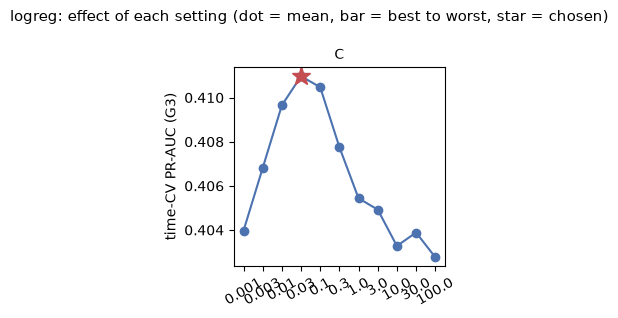

In [14]:
SENS_SET = TUNE_ON or FEATURE_SETS[-1]
sens = experiment.setting_sensitivity(model.NAME, SENS_SET, LOG_PATH)
if sens.empty:
    print("Fewer than two values tried for every setting: nothing to show.")
else:
    display(sens.round(4))
    settings_ = list(dict.fromkeys(sens["setting"]))
    n = len(settings_)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.2), sharey=True, squeeze=False)
    for ax, name in zip(axes[0], settings_):
        part = sens[sens["setting"] == name].reset_index(drop=True)
        x = range(len(part))
        ax.vlines(x, part["worst"], part["best"], color="#BBBBBB", lw=4)
        ax.plot(x, part["mean"], "o-", color="#4C72B0")
        picked = chosen[SENS_SET].get(name)
        for i, v in enumerate(part["value"]):
            if v == picked or (picked is None and v == "none"):
                ax.plot(i, part.loc[i, "best"], "*", ms=14, color="#C44E52")
        ax.set_xticks(list(x), [str(v) for v in part["value"]], rotation=30)
        ax.set_title(name, fontsize=10)
    axes[0][0].set_ylabel(f"time-CV PR-AUC ({SENS_SET})")
    fig.suptitle(f"{model.NAME}: effect of each setting (dot = mean, bar = best to worst, star = chosen)", fontsize=11)
    fig.tight_layout()
    plt.show()

## 6. Feature importance

For the chosen settings on `IMPORTANCE_SET` (G3 by default), refit on the training block exactly as in the seed-0
validation run (cached in `results/models/`, so this runs once), then measure:

- **Permutation importance:** how much validation PR-AUC drops when one input column is shuffled (on
  `IMPORTANCE_ROWS` validation rows). It means the same thing for every model, so it can be compared across notebooks.
- **Built-in importance:** the absolute coefficient of each input (inputs are standardised; one-hot and missing-indicator columns are summed back to their raw column).

Correlated columns share credit: shuffling one leaves its near-copy in place, so a small drop does not prove a column
is useless. Importances describe what this model relies on, not causes of fraud. The table is also saved to
`results/importance/` for `10_model_comparison.ipynb`.

In [15]:
cols = sets[IMPORTANCE_SET]
fitted, pipe = experiment.fit_final(model, lambda: make_pipeline(cols), df, train_idx, chosen[IMPORTANCE_SET],
                                    IMPORTANCE_SET, seed=0, cache_dir=MODELS_DIR)
X_val = pipe.transform(df.iloc[val_idx])
y_val = df["isFraud"].iloc[val_idx].to_numpy()
group_of = importance.feature_groups(spec)

perm = importance.permutation(fitted, X_val, y_val, cols, n_rows=IMPORTANCE_ROWS, seed=0)
built_in = importance.intrinsic(model, fitted, list(X_val.columns), cols)
imp = perm[["pr_auc_drop"]].assign(group=[group_of.get(c, "?") for c in perm.index])
if built_in is not None:
    imp["built_in"] = built_in
    imp["built_in_share"] = built_in / built_in.sum()
imp = imp.sort_values("pr_auc_drop", ascending=False)
print(f"PR-AUC on the {min(IMPORTANCE_ROWS, len(val_idx)):,} rows used: {perm['base_pr_auc'].iloc[0]:.4f} "
      f"(built-in importance: {model.IMPORTANCE or 'none'})")
IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)
imp.assign(model=model.NAME, feature_set=IMPORTANCE_SET).to_csv(IMPORTANCE_DIR / f"{model.NAME}_{IMPORTANCE_SET}.csv")
display(imp.head(20).round(4))

PR-AUC on the 20,000 rows used: 0.3504 (built-in importance: absolute coefficient (standardised inputs))


,pr_auc_drop,group,built_in,built_in_share
feature,,,,
fe_D1n,0.1743,G1_row_level,1.4787,0.0174
C14,0.1699,G0_raw,3.3504,0.0394
D1,0.1485,G0_raw,1.5616,0.0183
C11,0.1378,G0_raw,2.9986,0.0352
C4,0.0575,G0_raw,0.9202,0.0108
V189,0.0535,G0_raw,0.3366,0.0040
D10,0.0526,G0_raw,0.6252,0.0073
fe_D10n,0.0509,G1_row_level,0.7367,0.0087
V257,0.0446,G0_raw,0.4913,0.0058


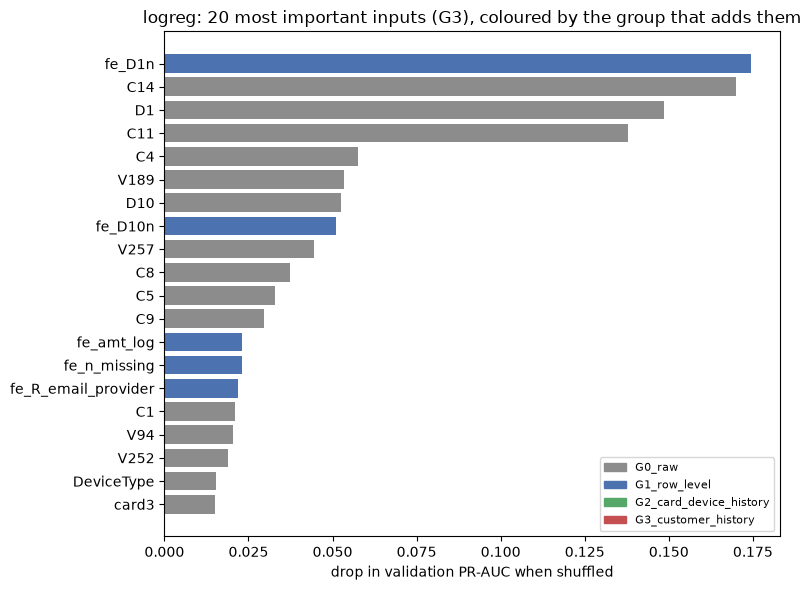

Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):


,sum,count
group,,
G0_raw,1.1696,197
G1_row_level,0.3823,27
G2_card_device_history,0.0420,10
G3_customer_history,0.0077,18


In [16]:
top = imp.head(20).iloc[::-1]
colors = {"G0_raw": "#8C8C8C", "G1_row_level": "#4C72B0", "G2_card_device_history": "#55A868",
          "G3_customer_history": "#C44E52"}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["pr_auc_drop"], color=[colors.get(g, "#999999") for g in top["group"]])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, list(colors), fontsize=8, loc="lower right")
ax.set_xlabel("drop in validation PR-AUC when shuffled")
ax.set_title(f"{model.NAME}: 20 most important inputs ({IMPORTANCE_SET}), coloured by the group that adds them")
fig.tight_layout()
plt.show()

print("Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):")
display(imp.groupby("group")["pr_auc_drop"].agg(["sum", "count"]).sort_values("sum", ascending=False).round(4))

## 7. Findings

Write this after running, quoting only numbers from the tables above:

- Which feature set scores best, and how much each step adds (G0 → G1 → G2 → G3; table 5.3).
- How known and unknown customers compare, and whether history features (G2, G3) help mainly known ones (5.4).
- Whether the chosen settings sit at the edge of the grid (a sign the grid should be widened).
- Anything unusual, such as a large spread between seeds.
- Which settings matter most (5.5): where the mean moves a lot across values, and where it barely moves.
- Which inputs matter most (section 6), whether the engineered features (G1–G3) are among them, and whether that fits
  the EDA (for example the customer-history features mattering mainly for known customers).